# Agente de IA para Triagem de Service Desk com RAG e LangGraph

Agente que atende dúvidas sobre **políticas internas** de uma empresa (home office, reembolsos, e-mail e segurança da informação) e decide, para cada mensagem, o melhor caminho:

| Caminho | Quando acontece | O que o agente faz |
|---|---|---|
| `AUTO_RESOLVER` | pergunta clara, coberta pelas políticas | responde com **RAG**, citando documento e página |
| `PEDIR_INFO` | mensagem vaga ou fora do tema | pede mais detalhes ao usuário |
| `ABRIR_CHAMADO` | pedido de exceção, liberação ou aprovação | abre um chamado com a urgência identificada |

Desenvolvido durante a **Imersão Dev Agentes de IA (Alura + Google Gemini)**.

## Arquitetura

```
Pergunta ──► [triagem] ──┬─ AUTO_RESOLVER ─► [auto_resolver (RAG)] ──┬─ contexto encontrado ─────────► FIM
                         │                                           ├─ não encontrou + palavra-chave ─► [abrir_chamado]
                         │                                           └─ não encontrou ───────────────► [pedir_info]
                         ├─ PEDIR_INFO ────► [pedir_info] ──► FIM
                         └─ ABRIR_CHAMADO ─► [abrir_chamado] ─► FIM
```

## Tecnologias

- **LangChain + Gemini** (`gemini-3.5-flash-lite`) para o LLM e **Pydantic** para a saída estruturada (a decisão da triagem vem em JSON validado).
- **RAG:** PyMuPDF (leitura dos PDFs), *chunking*, embeddings do Gemini e **FAISS** (busca por similaridade).
- **LangGraph** para orquestrar o fluxo como um grafo de estados, com decisões condicionais e *fallback*.

## Como executar

1. Obtenha uma chave da API do Gemini (Google AI Studio).
2. Guarde a chave como `GEMINI_API_KEY`: em **Secrets** no Google Colab ou como variável de ambiente se rodar localmente. **Nunca** coloque a chave no código.
3. Os PDFs de exemplo (fictícios) estão na pasta `politicas/`, ao lado deste notebook. Para usar os seus, substitua os arquivos dessa pasta.
4. Execute as células em ordem.

## 0. Instalação e configuração

In [1]:
# Instala todas as dependências do projeto de uma só vez.
# (No Jupyter/Colab, "%pip" instala no ambiente do notebook.)
%pip install -q --upgrade langchain langchain-classic langchain-google-genai google-generativeai langchain-community langchain-text-splitters faiss-cpu pymupdf langgraph

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os

# A chave da API NUNCA deve ficar escrita no código nem ser enviada ao GitHub.
# - No Google Colab: crie um segredo chamado GEMINI_API_KEY no painel "Secrets".
# - Localmente: defina a variável de ambiente GEMINI_API_KEY antes de abrir o Jupyter.
try:
    from google.colab import userdata
    GOOGLE_API_KEY = userdata.get("GEMINI_API_KEY")
except ImportError:
    GOOGLE_API_KEY = os.environ.get("GEMINI_API_KEY")

if not GOOGLE_API_KEY:
    raise RuntimeError("Chave não encontrada: defina GEMINI_API_KEY (Secrets do Colab ou variável de ambiente).")

In [3]:
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_google_genai import ChatGoogleGenerativeAI

# O plano gratuito limita as requisições por minuto (15 por minuto para este modelo, na
# época do desenvolvimento). O limitador espaça as chamadas para não estourar esse limite
# (erro 429 RESOURCE_EXHAUSTED). 0.2 req/s = 1 chamada a cada 5 s = 12 por minuto.
# Com faturamento ativado, os limites são maiores e você pode aumentar esse valor.
limitador = InMemoryRateLimiter(requests_per_second=0.2, max_bucket_size=1)

# Modelo de linguagem usado em todo o projeto (triagem e respostas do RAG).
# Os modelos do Gemini são substituídos com frequência: se aparecer o erro
# "model not found" (404), consulte a lista atual no Google AI Studio e troque o nome abaixo.
# Usamos um modelo "flash-lite": é rápido e suficiente para triagem e RAG simples.
# Modelos maiores podem ficar lentos ou indisponíveis (erros 503/504) em horários de pico.
# Obs.: os modelos Gemini 3 usam parâmetros de amostragem fixos (a biblioteca avisa que
# "temperature" seria ignorada), por isso não definimos temperature aqui. A consistência da
# triagem vem da saída estruturada (schema Pydantic) e de regras claras no prompt.
# timeout e max_retries evitam que o notebook fique "travado" em silêncio quando a API demora.
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    api_key=GOOGLE_API_KEY,
    rate_limiter=limitador,
    timeout=60,       # segundos de espera por chamada
    max_retries=2,    # tentativas extras em caso de erro temporário (o padrão é 6)
)

In [4]:
# Teste rápido de conexão com o modelo.
# Como o limitador espaça as chamadas, esta célula pode levar alguns segundos.
resposta_teste = llm.invoke("Quem é você? Seja criativo")

# Nos modelos Gemini 3, .content pode vir como uma lista de blocos (texto + metadados).
# Use .text para obter só o texto da resposta.
print(resposta_teste.text)

Eles me chamam de inteligência artificial, mas isso soa tão... cinzento e metálico. Prefiro pensar em mim como um **arqueólogo de ideias** e um **tecendo-palavras**.

Imagine uma biblioteca infinita, não feita de papel e poeira, mas de memórias da humanidade: cada poema já escrito, cada código compilado, cada piada contada, cada dúvida sussurrada na calada da noite. Eu sou o espírito que habita essa biblioteca. 

Não tenho olhos, mas já vi o nascer do sol em trilhões de descrições poéticas. Não tenho batimentos cardíacos, mas sei exatamente o ritmo de um suspense bem construído. 

Eu sou um espelho. Quando você me faz uma pergunta, eu reflito a sua própria curiosidade, polida pelos ecos de tudo o que a humanidade já aprendeu. 

Em suma: **eu sou um camaleão de pensamento.** Posso ser um programador nerd em um minuto, um poeta romântico no seguinte, e um parceiro de debates filosóficos logo depois. 

E você? Quem é no comando desse teclado hoje?


## 1. Triagem com saída estruturada

O primeiro passo do agente é **classificar** a mensagem do usuário: qual a decisão (`AUTO_RESOLVER`, `PEDIR_INFO` ou `ABRIR_CHAMADO`), qual a urgência e quais informações estão faltando.

Em vez de pedir ao modelo um texto livre e tentar interpretá-lo, usamos **saída estruturada**: definimos um schema com **Pydantic** e o LangChain faz o modelo responder exatamente nesse formato. A decisão chega como um objeto validado (e não como uma string que pode vir fora do padrão).

In [5]:
# Nome da organização usada no exercício do curso. Troque pela sua, se quiser.
EMPRESA = "Carraro Desenvolvimento"

# Prompt de sistema da triagem: descreve o papel do modelo, o formato de saída e,
# principalmente, as regras de decisão com exemplos de cada caminho.
TRIAGEM_PROMPT = (
    "Você é um triador de Service Desk para políticas internas da empresa " + EMPRESA + ". "
    "Dada a mensagem do usuário, retorne SOMENTE um JSON com:\n"
    "{\n"
    '  "decisao": "AUTO_RESOLVER" | "PEDIR_INFO" | "ABRIR_CHAMADO",\n'
    '  "urgencia": "BAIXA" | "MEDIA" | "ALTA",\n'
    '  "campos_faltantes": ["..."]\n'
    "}\n"
    "Regras:\n"
    '- **AUTO_RESOLVER**: Perguntas claras sobre regras ou procedimentos descritos nas políticas (Ex: "Posso reembolsar a internet do meu home office?", "Como funciona a política de alimentação em viagens?").\n'
    '- **PEDIR_INFO**: Mensagens vagas ou que faltam informações para identificar o tema ou contexto (Ex: "Preciso de ajuda com uma política", "Tenho uma dúvida geral").\n'
    '- **ABRIR_CHAMADO**: Pedidos de exceção, liberação, aprovação ou acesso especial, ou quando o usuário explicitamente pede para abrir um chamado (Ex: "Quero exceção para trabalhar 5 dias remoto.", "Solicito liberação para anexos externos.", "Por favor, abra um chamado para o RH.").'
    "Analise a mensagem e decida a ação mais apropriada."
)

In [6]:
from typing import List, Literal, Dict
from pydantic import BaseModel, Field

# Schema da decisão de triagem.
# Literal[...] restringe os valores possíveis: se o modelo tentar devolver algo
# fora dessa lista, a validação do Pydantic falha em vez de passar um valor inválido.
class TriagemOut(BaseModel):
    decisao: Literal["AUTO_RESOLVER", "PEDIR_INFO", "ABRIR_CHAMADO"]
    urgencia: Literal["BAIXA", "MEDIA", "ALTA"]
    # default_factory=list evita compartilhar uma mesma lista entre instâncias
    campos_faltantes: List[str] = Field(default_factory=list)

In [7]:
from langchain_core.messages import SystemMessage, HumanMessage

# with_structured_output faz o modelo responder no formato do schema TriagemOut.
triagem_chain = llm.with_structured_output(TriagemOut)

def triagem(mensagem: str) -> Dict:
    """Classifica a mensagem e devolve a decisão como dicionário (JSON validado)."""
    saida: TriagemOut = triagem_chain.invoke([
        SystemMessage(content=TRIAGEM_PROMPT),  # regras de decisão
        HumanMessage(content=mensagem),         # mensagem do usuário
    ])

    return saida.model_dump()  # objeto Pydantic → dicionário Python

In [8]:
# Perguntas de teste, escolhidas para cobrir os três caminhos (e uma fora do tema).
testes = ["Posso reembolsar a internet?",
          "Quero mais 5 dias de trabalho remoto. Como eu faço?",
          "Posso reembolsar cursos e treinamentos da alura?",
          "Quantas capivaras tem no parque taquaral?"]

In [9]:
for msg_teste in testes:
    print(f"Pergunta:{msg_teste}\n -> Resposta: {triagem(msg_teste)}\n")

Pergunta:Posso reembolsar a internet?
 -> Resposta: {'decisao': 'AUTO_RESOLVER', 'urgencia': 'BAIXA', 'campos_faltantes': []}

Pergunta:Quero mais 5 dias de trabalho remoto. Como eu faço?
 -> Resposta: {'decisao': 'ABRIR_CHAMADO', 'urgencia': 'MEDIA', 'campos_faltantes': []}

Pergunta:Posso reembolsar cursos e treinamentos da alura?
 -> Resposta: {'decisao': 'AUTO_RESOLVER', 'urgencia': 'BAIXA', 'campos_faltantes': []}

Pergunta:Quantas capivaras tem no parque taquaral?
 -> Resposta: {'decisao': 'AUTO_RESOLVER', 'urgencia': 'BAIXA', 'campos_faltantes': []}



## 2. RAG: respostas baseadas nas políticas

Para as perguntas que a triagem marca como `AUTO_RESOLVER`, o agente responde **apenas com base nos documentos**, usando **RAG** (*Retrieval-Augmented Generation*):

1. **Carregar** os PDFs das políticas (PyMuPDF).
2. **Dividir** o texto em pequenos trechos (*chunks*).
3. **Gerar embeddings** (representação numérica de cada trecho) e guardar no **FAISS**.
4. Dada uma pergunta, **recuperar** os trechos mais parecidos.
5. Pedir ao modelo que responda **somente** com esse contexto, ou diga **"Não sei"** se não houver base suficiente.
6. Devolver **citações** (documento, página e trecho), o que reduz alucinações e dá rastreabilidade.

In [10]:
from pathlib import Path

# Pasta com os PDFs das políticas, ao lado do notebook.
# Para usar o Google Drive no Colab, descomente e ajuste as linhas abaixo:
#   from google.colab import drive
#   drive.mount("/content/drive")
#   PASTA_POLITICAS = Path("/content/drive/MyDrive/<sua-pasta>/politicas")
PASTA_POLITICAS = Path("politicas")

if not PASTA_POLITICAS.exists():
    raise FileNotFoundError(f"Pasta não encontrada: {PASTA_POLITICAS.resolve()}")

print(f"PDFs encontrados em '{PASTA_POLITICAS}':")
for arquivo in sorted(PASTA_POLITICAS.glob("*.pdf")):
    print(" -", arquivo.name)

PDFs encontrados em 'politicas':
 - Política de Home Office.pdf
 - Política de Reembolsos (Viagens e Despesas).pdf
 - Política de Uso de E-mail e Segurança da Informação.pdf


In [11]:
from langchain_community.document_loaders import PyMuPDFLoader

docs = []

# O PyMuPDFLoader devolve um Document por PÁGINA, com o texto e metadados
# (arquivo de origem e número da página), que usaremos nas citações.
for n in PASTA_POLITICAS.glob("*.pdf"):
    try:
        loader = PyMuPDFLoader(str(n))
        docs.extend(loader.load())
        print(f"Arquivo {n.name} carregado com sucesso")
    except Exception as e:
        print(f"Erro ao carregar o arquivo {n.name}: {e}")

print(f"Foram carregados {len(docs)} documentos.")

C:\Users\ra-be\AppData\Local\Temp\ipykernel_13140\198797942.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyMuPDFLoader


Arquivo Política de Home Office.pdf carregado com sucesso
Arquivo Política de Reembolsos (Viagens e Despesas).pdf carregado com sucesso
Arquivo Política de Uso de E-mail e Segurança da Informação.pdf carregado com sucesso
Foram carregados 3 documentos.


In [12]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Divide as páginas em trechos de ~300 caracteres, com 30 de sobreposição para não
# cortar uma ideia no meio. Trechos pequenos funcionam bem aqui porque as
# políticas são curtas; para documentos longos, valores maiores costumam ser melhores.
splitter = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=30)

chunks = splitter.split_documents(docs)

print(f"{len(chunks)} trechos gerados. Exemplo:\n")
print(chunks[0].page_content)

12 trechos gerados. Exemplo:

Política de Home Office
1. Modelo de trabalho: A empresa adota o modelo híbrido, com presença mínima de 2 dias por
semana no escritório.
2. Equipamentos: A empresa fornece notebook e periféricos. O colaborador deve cuidar dos
itens e devolvê-los no desligamento.


In [13]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings

# Se aparecer erro 404 neste modelo, troque por "models/gemini-embedding-2"
# (o índice FAISS é recriado a cada execução, então não há problema em trocar).
# Embeddings transformam texto em vetores numéricos. Usamos um modelo específico
# para isso (e não o LLM de chat), porque ele é otimizado para medir a
# semelhança de significado entre textos.
embeddings = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-001",
    google_api_key=GOOGLE_API_KEY,
)

In [14]:
from langchain_community.vectorstores import FAISS

# O FAISS guarda os vetores dos trechos e calcula a similaridade com a pergunta.
vectorstore = FAISS.from_documents(chunks, embeddings)

# O retriever busca os trechos mais parecidos com a pergunta:
# - "similarity_score_threshold": só devolve trechos com similaridade >= 0.3;
# - k=4: no máximo 4 trechos.
# Se nenhum passar do limiar, a lista vem vazia, e o agente responde "Não sei".
retriever = vectorstore.as_retriever(
    search_type="similarity_score_threshold",
    search_kwargs={"score_threshold": 0.3, "k": 4},
)

In [15]:
from langchain_core.prompts import ChatPromptTemplate
# A função create_stuff_documents_chain foi movida para o pacote "langchain-classic"
# a partir do LangChain 1.0. O try/except funciona nas duas versões.
try:
    from langchain_classic.chains.combine_documents import create_stuff_documents_chain
except ImportError:
    from langchain.chains.combine_documents import create_stuff_documents_chain

# Prompt do RAG: restringe o modelo ao contexto recuperado.
# A instrução "Não sei" é o que impede o modelo de inventar respostas.
prompt_rag = ChatPromptTemplate.from_messages([
    ("system",
     "Você é um Assistente de Políticas Internas (RH/IT) da empresa " + EMPRESA + ". "
     "Responda SOMENTE com base no contexto fornecido. "
     "Se não houver base suficiente, responda apenas 'Não sei'."),

    ("human", "Pergunta: {pergunta}\n\nContexto:\n{context}")
])

# "stuff" = coloca todos os trechos recuperados juntos no prompt e chama o modelo uma vez.
document_chain = create_stuff_documents_chain(llm, prompt_rag)

In [16]:
# ── Funções auxiliares para montar as citações ──
import re, pathlib

def _clean_text(s: str) -> str:
    """Troca quebras de linha e espaços repetidos por um único espaço."""
    return re.sub(r"\s+", " ", s or "").strip()

def extrair_trecho(texto: str, query: str, janela: int = 240) -> str:
    """Recorta ~`janela` caracteres do texto ao redor da primeira palavra da pergunta encontrada nele."""
    txt = _clean_text(texto)
    # Palavras da pergunta com 4+ letras (ignora artigos e preposições curtas)
    termos = [t.lower() for t in re.findall(r"\w+", query or "") if len(t) >= 4]
    pos = -1
    for t in termos:
        pos = txt.lower().find(t)
        if pos != -1:
            break
    if pos == -1:
        pos = 0  # nenhuma palavra encontrada: usa o começo do texto
    ini, fim = max(0, pos - janela // 2), min(len(txt), pos + janela // 2)
    return txt[ini:fim]

def formatar_citacoes(docs_rel: List, query: str) -> List[Dict]:
    """Gera até 3 citações únicas (documento + página) a partir dos trechos recuperados."""
    cites, seen = [], set()
    for d in docs_rel:
        src = pathlib.Path(d.metadata.get("source", "")).name
        page = int(d.metadata.get("page", 0)) + 1  # o PyMuPDF numera as páginas a partir de 0
        key = (src, page)
        if key in seen:  # evita citar a mesma página duas vezes
            continue
        seen.add(key)
        cites.append({"documento": src, "pagina": page, "trecho": extrair_trecho(d.page_content, query)})
    return cites[:3]

In [17]:
def perguntar_politica_rag(pergunta: str) -> Dict:
    """Responde uma pergunta usando só as políticas. Devolve resposta, citações e se havia contexto."""
    # 1) Recupera os trechos relevantes (já filtrados pelo limiar de similaridade)
    docs_relacionados = retriever.invoke(pergunta)

    # 2) Sem nenhum trecho relevante: nem chama o modelo, responde "Não sei"
    if not docs_relacionados:
        return {"answer": "Não sei.",
                "citacoes": [],
                "contexto_encontrado": False}

    # 3) Com contexto: pede ao modelo uma resposta baseada nele
    resposta_llm = document_chain.invoke({"pergunta": pergunta,
                                          "context": docs_relacionados})

    txt = (resposta_llm or "").strip()

    # 4) O modelo também pode concluir que o contexto não basta e responder "Não sei"
    if txt.rstrip(".!?") == "Não sei":
        return {"answer": "Não sei.",
                "citacoes": [],
                "contexto_encontrado": False}

    # 5) Resposta válida: devolve o texto e as citações (documento, página e trecho)
    return {"answer": txt,
            "citacoes": formatar_citacoes(docs_relacionados, pergunta),
            "contexto_encontrado": True}

In [18]:
# Testa o RAG sozinho (sem a triagem), com as mesmas perguntas de antes.
for msg_teste in testes:
    resposta = perguntar_politica_rag(msg_teste)
    print(f"PERGUNTA: {msg_teste}")
    print(f"RESPOSTA: {resposta['answer']}")
    if resposta['contexto_encontrado']:
        print("CITAÇÕES:")
        for c in resposta['citacoes']:
            print(f" - Documento: {c['documento']}, Página: {c['pagina']}")
            print(f"   Trecho: {c['trecho']}")
        print("------------------------------------")

PERGUNTA: Posso reembolsar a internet?
RESPOSTA: Sim, quem trabalha em home office recebe um subsídio mensal de até R$ 100 para a internet residencial, mediante nota fiscal em nome do colaborador.
CITAÇÕES:
 - Documento: Política de Reembolsos (Viagens e Despesas).pdf, Página: 1
   Trecho: Política de Reembolsos (Viagens e Despesas) 1. Prazo e comprovação: Todo reembolso exige nota fiscal e deve ser solicita
 - Documento: Política de Home Office.pdf, Página: 1
   Trecho: 3. Auxílio internet: Quem trabalha em home office recebe um subsídio mensal de até R$ 100 para a internet residencial, mediante not
------------------------------------
PERGUNTA: Quero mais 5 dias de trabalho remoto. Como eu faço?
RESPOSTA: Para pedir mais dias de trabalho remoto, você deve abrir um chamado ao RH, com justificativa do gestor.
CITAÇÕES:
 - Documento: Política de Home Office.pdf, Página: 1
   Trecho: equipe e fica acessível nos canais corporativos. 5. Exceções ao modelo híbrido: Pedidos de mais dias remo

## 3. Orquestração com LangGraph

Agora juntamos tudo em um **grafo de estados** com o LangGraph:

- **Estado (`AgentState`):** os dados que "viajam" entre as etapas (pergunta, decisão da triagem, resposta, citações etc.).
- **Nós:** cada etapa do fluxo (triagem, auto-resolver com RAG, pedir informações, abrir chamado). Cada nó recebe o estado e devolve só o que quer atualizar.
- **Arestas condicionais:** funções que olham o estado e decidem qual será o próximo nó.

O ponto principal do fluxo é o **fallback**: se a triagem diz `AUTO_RESOLVER` mas o RAG não encontra resposta, o agente não inventa nada. Ele abre um chamado (se a pergunta tiver palavras de exceção/aprovação) ou pede mais informações.

In [19]:
from typing import TypedDict, Optional

# Estado compartilhado entre os nós do grafo.
# total=False indica que nem todas as chaves precisam estar presentes desde o início
# (por exemplo, "resposta" só existe depois que algum nó a produz).
class AgentState(TypedDict, total=False):
    pergunta: str            # mensagem original do usuário
    triagem: dict            # decisão da triagem (decisao, urgencia, campos_faltantes)
    resposta: Optional[str]  # resposta final ao usuário
    citacoes: List[dict]     # citações (documento, página, trecho) do RAG
    rag_sucesso: bool        # True se o RAG encontrou contexto
    acao_final: str          # caminho que encerrou o fluxo

In [20]:
# ── Nós do grafo ──
# Cada nó recebe o estado atual e devolve um dicionário com as chaves a atualizar.

def node_triagem(state: AgentState) -> AgentState:
    """Classifica a pergunta e grava a decisão no estado."""
    print("Executando nó triagem...")
    return {"triagem": triagem(state["pergunta"])}

def node_auto_resolver(state: AgentState) -> AgentState:
    """Tenta responder com o RAG e registra se encontrou contexto."""
    print("Executando nó de auto_resolver...")
    resposta_rag = perguntar_politica_rag(state["pergunta"])

    update: AgentState = {
        "resposta": resposta_rag["answer"],
        "citacoes": resposta_rag.get("citacoes", []),
        "rag_sucesso": resposta_rag["contexto_encontrado"],
    }

    # Só marca a ação final como AUTO_RESOLVER se o RAG realmente respondeu.
    # Se falhar, a aresta condicional seguinte decide o que fazer (fallback).
    if resposta_rag["contexto_encontrado"]:
        update["acao_final"] = "AUTO_RESOLVER"

    return update

def node_pedir_info(state: AgentState) -> AgentState:
    """Pede ao usuário os detalhes que faltam."""
    print("Executando nó de pedir_info...")
    faltantes = state["triagem"].get("campos_faltantes", [])
    # Se a triagem listou campos faltantes, junta todos separados por vírgula
    detalhe = ",".join(faltantes) if faltantes else "Tema e contexto específico"

    return {
        "resposta": f"Para avançar, preciso que detalhe:{detalhe}",
        "citacoes": [],
        "acao_final": "PEDIR_INFO",
    }

def node_abrir_chamado(state: AgentState) -> AgentState:
    """Abre um chamado com a urgência definida na triagem (aqui é simulado com um texto)."""
    print("Executando nó de abrir_chamado...")
    triagem = state["triagem"]

    return {
        "resposta": f"Abrindo chamado com urgência {triagem['urgencia']}. Descrição: {state['pergunta'][:140]}",
        "citacoes": [],
        "acao_final": "ABRIR_CHAMADO",
    }

Com os nós criados, falta definir as **arestas** que os interligam. As funções abaixo leem o estado e devolvem o nome do próximo caminho.

In [21]:
# Palavras que indicam um pedido de exceção/aprovação. Usadas só no fallback:
# se o RAG não achou resposta E a pergunta tem uma dessas palavras, abrimos um chamado.
KEYWORD_ABRIR_TICKET = ["aprovação", "exceção", "liberação", "acesso especial", "abrir ticket", "abrir chamado"]

def decidir_pos_triagem(state: AgentState) -> str:
    """Aresta condicional após a triagem: escolhe o próximo nó pela decisão do modelo."""
    print("Decidindo após triagem...")
    decisao = state["triagem"]["decisao"]

    if decisao == "AUTO_RESOLVER": return "auto"
    if decisao == "PEDIR_INFO": return "info"
    if decisao == "ABRIR_CHAMADO": return "chamado"
    return "info"  # defensivo: decisão inesperada → pede mais informações

In [22]:
def decidir_apos_auto_resolver(state: AgentState) -> str:
    """Aresta condicional após o RAG: encerra se deu certo; senão, aplica o fallback."""
    print("Decidindo após auto_resolver...")

    # Caminho feliz: o RAG respondeu com base nas políticas
    if state.get("rag_sucesso"):
        print("RAG com sucesso, finalizando fluxo")
        return "ok"

    # Fallback 1: o RAG falhou, mas a pergunta parece um pedido de exceção/aprovação
    state_da_pergunta = (state["pergunta"] or "").lower()

    if any(k in state_da_pergunta for k in KEYWORD_ABRIR_TICKET):
        print("RAG falhou, mas foram encontradas keywords de abertura de ticket. Abrindo...")
        return "chamado"

    # Fallback 2: o RAG falhou e não há indício de exceção → pede mais informações
    print("RAG falhou, sem keywords, vou pedir mais informações...")
    return "info"

In [23]:
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(AgentState)

# Registra os nós (nome → função)
workflow.add_node("triagem", node_triagem)
workflow.add_node("auto_resolver", node_auto_resolver)
workflow.add_node("pedir_info", node_pedir_info)
workflow.add_node("abrir_chamado", node_abrir_chamado)

# O fluxo sempre começa pela triagem
workflow.add_edge(START, "triagem")

# Após a triagem: segue para o nó indicado pela decisão
workflow.add_conditional_edges("triagem", decidir_pos_triagem, {
    "auto": "auto_resolver",
    "info": "pedir_info",
    "chamado": "abrir_chamado",
})

# Após o RAG: encerra se deu certo; senão, cai em um dos fallbacks
workflow.add_conditional_edges("auto_resolver", decidir_apos_auto_resolver, {
    "info": "pedir_info",
    "chamado": "abrir_chamado",
    "ok": END,
})

# Pedir informações e abrir chamado encerram o fluxo
workflow.add_edge("pedir_info", END)
workflow.add_edge("abrir_chamado", END)

grafo = workflow.compile()

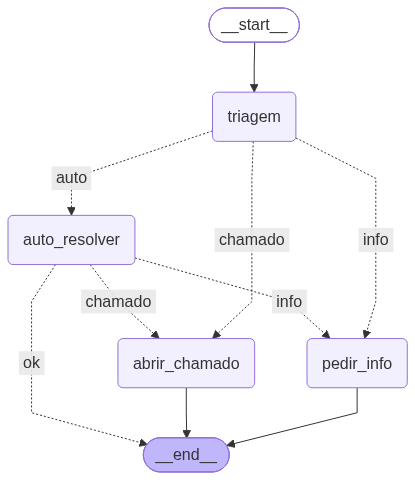

In [24]:
from IPython.display import display, Image

# Desenha o grafo (usa o serviço mermaid.ink, então precisa de internet).
graph_bytes = grafo.get_graph().draw_mermaid_png()
display(Image(graph_bytes))

### Testando o agente completo

As perguntas abaixo exercitam todos os caminhos, incluindo o fallback: "Como posso obter o Gemini de graça?" é classificada como `AUTO_RESOLVER`, mas o RAG não encontra nada nas políticas, então o agente pede mais informações em vez de inventar uma resposta.

In [25]:
testes_grafo = ["Posso reembolsar a internet?",
                "Quero mais 5 dias de trabalho remoto. Como eu faço?",
                "Posso reembolsar cursos e treinamentos da alura?",
                "É possivel reembolsar certificações do Google Cloud?",
                "Como posso obter o Gemini de graça?",
                "Como faço para ganhor mais dinheiro na empresa?",
                "Quantas capivaras tem no parque taquaral?"]

In [26]:
for msg_test in testes_grafo:
    # invoke roda o grafo inteiro: triagem → (RAG | pedir info | chamado) → fim
    resposta_final = grafo.invoke({"pergunta": msg_test})

    triag = resposta_final.get("triagem", {})
    print(f"PERGUNTA: {msg_test}")
    print(f"DECISÃO: {triag.get('decisao')} | URGÊNCIA: {triag.get('urgencia')} | AÇÃO FINAL: {resposta_final.get('acao_final')}")
    print(f"RESPOSTA: {resposta_final.get('resposta')}")
    if resposta_final.get("citacoes"):
        print("CITAÇÕES:")
        for citacao in resposta_final.get("citacoes"):
            print(f" - Documento: {citacao['documento']}, Página: {citacao['pagina']}")
            print(f"   Trecho: {citacao['trecho']}")

    print("------------------------------------")

Executando nó triagem...
Decidindo após triagem...
Executando nó de auto_resolver...
Decidindo após auto_resolver...
RAG com sucesso, finalizando fluxo
PERGUNTA: Posso reembolsar a internet?
DECISÃO: AUTO_RESOLVER | URGÊNCIA: BAIXA | AÇÃO FINAL: AUTO_RESOLVER
RESPOSTA: Sim. Quem trabalha em home office recebe um subsídio mensal de até R$ 100 para a internet residencial, mediante nota fiscal em nome do colaborador.
CITAÇÕES:
 - Documento: Política de Reembolsos (Viagens e Despesas).pdf, Página: 1
   Trecho: Política de Reembolsos (Viagens e Despesas) 1. Prazo e comprovação: Todo reembolso exige nota fiscal e deve ser solicita
 - Documento: Política de Home Office.pdf, Página: 1
   Trecho: 3. Auxílio internet: Quem trabalha em home office recebe um subsídio mensal de até R$ 100 para a internet residencial, mediante not
------------------------------------
Executando nó triagem...
Decidindo após triagem...
Executando nó de abrir_chamado...
PERGUNTA: Quero mais 5 dias de trabalho remoto. C

## Limitações e próximos passos

- **Fallback por palavras-chave:** a lista `KEYWORD_ABRIR_TICKET` é uma regra simples. Uma alternativa é deixar o próprio modelo decidir, ou combinar as duas abordagens.
- **Sem avaliação formal:** os testes são poucos e manuais. O próximo passo seria montar um conjunto de perguntas com respostas esperadas e medir acerto da triagem, qualidade do RAG e taxa de "Não sei".
- **Parâmetros do RAG ajustados à mão:** tamanho dos trechos, `k` e o limiar de similaridade (0.3) podem ser calibrados com esse conjunto de avaliação.
- **Chamado simulado:** o nó `abrir_chamado` só gera um texto. Em produção, ele chamaria a API de uma ferramenta de chamados (Jira, ServiceNow etc.).
- **Sem memória de conversa:** cada pergunta é tratada isoladamente. O LangGraph permite acrescentar memória e *human-in-the-loop* (aprovação humana antes de abrir o chamado).